# Cellohood Analyses - DLPFC

In this notebook we will reproduce results for the analysis of DLPFC dataset.

## Data Preparation

Download Cellohood artifacts from zenodo: #TODO. Then set `ZENODO_PATH` to a path to zenodo DLPFC Cellohood artifacts. This will ensure that all model / analyses artifacts will be reproducible:

In [1]:
#!/raid/immucan/immuw/cellohood-final/bin/python -m pip install numpy==1.22.0

In [2]:
import os

import pandas
import joblib

from ccs import ccs
import cellohood

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["CUDA_VISIBLE_DEVICES"] = ""


ZENODO_PATH = '/raid/immucan/immuw/cellohood_artifacts/DLPFC'
DATA_PATH = os.path.join(ZENODO_PATH, 'dlpfc_scvi.csv')
data_df = pandas.read_csv(DATA_PATH)


MARKER_COL_NAMES = [
    'SCVI5:0',
    'SCVI5:1',
    'SCVI5:2',
    'SCVI5:3',
    'SCVI5:4',
]


DISTANCE_THRESHOLD = 9.


LOAD_CELLO_BAG_DF = True
FULL_CELLO_BAG_DF_PATH = f'DLPFC_CB_{DISTANCE_THRESHOLD}'



POS_COL_NAMES = ['pos_x', 'pos_y']
IMAGE_ID_COLUMN = 'sample'
SAMPLE_COL_NAME = 'sample'

LOAD_CELLO_PREDICTION = True
CELLO_PREDICTION_PATH = f'DLPFC_CP_{DISTANCE_THRESHOLD}'

TRAIN_MODEL = False
SAVING_PATH = f'DLPFC_CELLOHOOD_MODEL_{DISTANCE_THRESHOLD}'

Now - let's load `CelloBagDf` - containing cell representations, positions, and bag ids:

In [3]:
if not LOAD_CELLO_BAG_DF:
    bag_cello_df = cellohood.transform_df_to_bag_cello_df(
        df_=data_df,
        image_id_column=IMAGE_ID_COLUMN,
        pos_col_names=POS_COL_NAMES,
        distance_threshold=DISTANCE_THRESHOLD,
        marker_col_names=MARKER_COL_NAMES,
    )
    cellohood.save_bag_cello_df(bag_cello_df=bag_cello_df, path=FULL_CELLO_BAG_DF_PATH, exist_ok=True)
else:
    bag_cello_df = cellohood.load_bag_cello_df(path=FULL_CELLO_BAG_DF_PATH)

Let's split the data into training / test splits. They are split by samples - so it's omitted for small datasets (by setting the `split_percentage` to `1.0`:

In [4]:
train_bag_cello_df, test_bag_cello_df = cellohood.split_bag_cello_df_by(
    bag_cello_df,
    by=SAMPLE_COL_NAME,
    split_percentage=1.,
)

Now - let's standardize the data:

In [5]:
standardized_cello_dfs = cellohood.standardize_bag_cello_df(
    train_bag_cello_df=train_bag_cello_df, 
    test_bag_cello_df=test_bag_cello_df,
    marker_col_names=MARKER_COL_NAMES,
)

Now - let's train / load the model (by default it's loading a model from Cellohood zenodo artifacts):

In [6]:
if TRAIN_MODEL:
    cello_train_result = cellohood.train(
        standardized_cello_dfs=standardized_cello_dfs,
        epoch_nb=100,
        use_cuda=True,
    )
    cellohood.save_cello_train_result(cello_train_result, SAVING_PATH)
else:
    cello_train_result = cellohood.load_cello_train_result(SAVING_PATH)

{'output_size': 5, 'max_neighborhood_size': 19, 'latent_size': 64, 'layer_size': 128, 'intermediate_layer_size': 256}


2026-03-17 14:20:59.792740: E tensorflow/stream_executor/cuda/cuda_driver.cc:271] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2026-03-17 14:20:59.792794: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:169] retrieving CUDA diagnostic information for host: rudy
2026-03-17 14:20:59.792805: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:176] hostname: rudy
2026-03-17 14:20:59.793002: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:200] libcuda reported version is: 535.230.2
2026-03-17 14:20:59.793043: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:204] kernel reported version is: 535.230.2
2026-03-17 14:20:59.793053: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:310] kernel version seems to match DSO: 535.230.2


/raid/immucan/immuw/cellohood-final/lib/python3.8/site-packages/keras/engine/training_v1.py:2079: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates=self.state_updates,
2026-03-17 14:21:00.583857: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Now - let's load / prepare Cellohood predictions:

In [7]:
if not LOAD_CELLO_PREDICTION:
    cello_prediction = cellohood.run_prediction_on_cello_df(
        cello_train_result,
        bag_cello_df,
    )
    !rm -r new_cache
    smoothed_df_result = cellohood.smooth_cellohood_prediction(
        cello_prediction,
        distance_threshold=DISTANCE_THRESHOLD,
        cache_path='new_cache',
    )
    !rm -r new_cache
    cellohood.save_cello_prediction(
        cello_prediction=smoothed_df_result,
        path=CELLO_PREDICTION_PATH,
    )
else: 
    smoothed_df_result = cellohood.load_cello_prediction(
        path=CELLO_PREDICTION_PATH,
    )

Now - let's run a PLDA analysis:

In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


decomposer = PCA()
plda_decomposed = decomposer.fit_transform(smoothed_df_result.cell_predictions[smoothed_df_result.cello_columns].values)

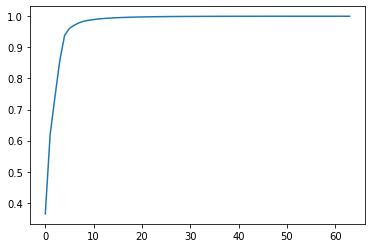

In [9]:
import matplotlib.pyplot as plt


plt.plot(decomposer.explained_variance_ratio_.cumsum())

As we may see a PLDA.50 consist of 1 dimension, and PLDA.75 - 2 dimensions. Now, let's prepare a list of `layers_` and `samples_` - useful for further analyses and plotting:

In [10]:
layers_ = sorted(list(set(bag_cello_df.cell_df['layer'])))
samples_ = list(set(bag_cello_df.cell_df['sample']))

true_layers = ['L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'WM']
true_layers_wu = true_layers + ['UNK']

Now - let's setup plotting parameters:

In [11]:
import seaborn as sns
import matplotlib


# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

# PATH_TO_ARIAL_FONT = '/raid/immucan/immuw/Arial.ttf'
# matplotlib.font_manager.fontManager.addfont(PATH_TO_ARIAL_FONT)  # if you need to add the font file
#plt.rcParams['font.family'] = 'Arial'

# Running a benchmark comparison:

Following the Cellcharter approach - we will use their testing samples together with ground truth counts:

In [12]:
SAMPLES = {
           '151508': 7, 
           '151509': 7, 
           '151510': 7, 
           '151669': 5, 
           '151670': 5, 
           '151671': 5, 
           '151674': 7, 
           '151675': 7, 
           '151676': 7
}

In [13]:
#!/raid/immucan/immuw/cellohood-final/bin/python3 -m pip install -U threadpoolctl

Now - let's fit the clusterers (seed makes results reproducible):

In [14]:
from collections import defaultdict
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score


from scipy.stats import ttest_rel
import numpy
import tqdm



NB_OF_RUNS = 10


# From Cellcharter paper
TEST_SAMPLES = [
    151507,
    151672,
    151673
]

NON_TEST_SAMPLES = [
    sample 
    for sample in sorted(bag_cello_df.cell_df['sample'].unique())
    if sample not in TEST_SAMPLES
]


current_random_seed = 42
sample_to_aris = defaultdict(list)
clusterers = []
variables = [0, 1]

train_cello_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES)]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    training_ld = plda_decomposed[
        bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES),
    ][:, variables]
    current_clusterer.fit(training_ld)
    clusterers.append(current_clusterer)
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        
        sample_ld = training_ld[train_cello_df['sample'] == sample][:, variables]
        sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        sample_preds = current_clusterer.predict(sample_ld)
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_aris[sample].append(current_ari)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:16<00:00,  1.69s/it]


In [15]:
train_means = []
for sample_id, sample in enumerate(sorted(sample_to_aris)):
    train_means.append(numpy.mean(sample_to_aris[sample]))

Now - we will do analogous computations for aggregated cell bag representation:

In [16]:
mean_markers = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].mean()
max_markers = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].max()
min_markers = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].min()

mm_ccs = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')['cellohood_neighborhood_cluster'].first()

agg_markers = pandas.concat([mean_markers, max_markers, min_markers], axis=1)

mean_marker_samples = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')['sample'].first()

NB_OF_RUNS = 10


current_random_seed = 42
sample_to_aris_mm = defaultdict(list)
clusterers_mm = []
variables = [0, 1]

train_cello_m_df = agg_markers[mean_marker_samples.apply(lambda x: x not in TEST_SAMPLES)]
mm_ccs_train = mm_ccs[mean_marker_samples.apply(lambda x: x not in TEST_SAMPLES)]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    training_ld = train_cello_m_df
    predictions = current_clusterer.fit_predict(training_ld)
    cc_to_pred = {cc: pred for cc, pred in zip(mm_ccs_train, predictions)}
    clusterers_mm.append(current_clusterer)
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        
        sample_preds = sample_non_unk_df['cellohood_neighborhood_cluster'].apply(lambda x: cc_to_pred[x])
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_aris_mm[sample].append(current_ari)

train_means_mm = []
for sample_id, sample in enumerate(sorted(sample_to_aris_mm)):
    train_means_mm.append(numpy.mean(sample_to_aris_mm[sample]))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:15<00:00,  1.56s/it]


Now - let's load results of the other methods (from Cellcharter artifacts):

In [17]:
import os


OTHER_RESULTS_PATH = os.path.join(ZENODO_PATH, 'other_paper_results')


method_to_results = {
    'UTAG': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_UTAG_hvgs1000_nlatent10_joint.csv')),
    'DR': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_DR-SC_svg2000_joint.csv')),
    'SEDR': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_SEDR_feat_hidden2_10_gcn_hidden2_16_pc10_gpu_joint.csv')),
    'Bayes Space': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_BayesSpace_hvg1000_pc15_gamma3_nrep5000_harmony-group_joint.csv')),
    'Stagate': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_STAGATE_hvgs5000_hidden_dim1024_nlatent30_gpu_joint.csv')),
    'Cellcharter': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_CellCharter_hvgs5000_nlatent5_nhoodlayers4_gpu_joint.csv')),
}

method_to_results_means = {
    key: value.values[value['Unnamed: 0'].apply(lambda x: x in NON_TEST_SAMPLES)][:, 1:].mean(axis=1)
    for key, value in method_to_results.items()
}

and compare results:

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch
import seaborn as sns
from scipy import stats

def compute_pvalues(data_lists, reference_idx):
    """
    Compute p-values comparing reference method to all others using two-sided t-test
    
    Parameters:
    -----------
    data_lists : list of lists
        Each inner list contains the scores for one method
    reference_idx : int
        Index of the reference method
        
    Returns:
    --------
    list of float
        P-values for each comparison (None for reference method)
    """
    pvalues = []
    reference_data = data_lists[reference_idx]
    
    for i, data in enumerate(data_lists):
        if i == reference_idx:
            pvalues.append(None)
        else:
            # Perform two-sided t-test
            _, pval = stats.ttest_rel(reference_data, data)
            pvalues.append(pval)
            
    return pvalues

def plot_boxplot_with_stats_2(data_lists, method_names, my_method_idx, 
                           figsize=(3, 2), my_method_color='lightblue',
                           other_methods_color='lightgray', sig_threshold=0.05):
    """
    Create a boxplot with significance bars connecting to a reference method.
    
    Parameters:
    -----------
    data_lists : list of lists
        Each inner list contains the scores for one method
    method_names : list of str
        Names of the methods
    my_method_idx : int
        Index of your method in the lists
    figsize : tuple
        Figure size
    my_method_color : str
        Color for your method's box
    other_methods_color : str
        Color for other methods' boxes
    sig_threshold : float
        Significance threshold for p-values
    """
    
    # Compute p-values
    pvalues = compute_pvalues(data_lists, my_method_idx)
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    
    # Create colors list
    colors = [other_methods_color] * len(method_names)
    colors[my_method_idx] = my_method_color
    
    # Create boxplot
    box_ratio = 1.25
    bplot = ax.boxplot(data_lists, patch_artist=True, positions=box_ratio * numpy.arange(len(colors)))
    
    # Color the boxes
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
    
    # Set the labels
    ax.set_xticklabels(method_names, rotation=30, ha='right', size=6)
    
    # Get the positions of boxes for connecting lines
    my_method_pos = my_method_idx + 1  # boxplot positions start at 1
    
    # Get the maximum value in the data for scaling
    max_val = max([max(sublist) for sublist in data_lists])
    min_val = min([min(sublist) for sublist in data_lists])
    plot_range = max_val - min_val
    
    # Space between bars
    step = plot_range * 0.1
    
    # Draw connecting lines and p-values
    for i, (pval, data) in enumerate(zip(pvalues, data_lists)):
        if i != my_method_idx:
            # Calculate height for this comparison
            curr_pos = i + 1  # boxplot positions start at 1
            height = max_val - 0.1 + step * (0.1 + abs(curr_pos)) * 1.5
            
            # Draw the line
            x1, x2 = sorted([my_method_pos, curr_pos])
            x1 = x1 * box_ratio - box_ratio
            x2 = x2 * box_ratio - box_ratio
            line = plt.hlines(y=height, xmin=x1, xmax=x2, color='black', linestyle='-', linewidth=0.6)
            
            # Add vertical line
            plt.vlines(x=x1, ymin=height - 0.01, ymax=height, color='black', linestyle='-', linewidth=0.6)
            plt.vlines(x=x2, ymin=height - 0.01, ymax=height, color='black', linestyle='-', linewidth=0.6)
            
            # Add p-value annotation
            text_pos = (x1 + x2) / 2
            
            # Format p-value
            if pval < 0.001:
                pval_text = 'p < 0.001'
            else:
                pval_text = f'p = {pval:.3f}'
            
            # Add asterisks for significance
            if pval < sig_threshold:
                asterisks = '*' * sum([pval < thresh for thresh in [0.05, 0.01, 0.001]])
                pval_text = f'{pval_text} ({asterisks})'
            
            plt.text(text_pos, height + step*0.1, pval_text, size=6,
                    horizontalalignment='center', verticalalignment='bottom')
    
    plt.plot([-0.5, 9.], [numpy.median(train_means)] * 2, '--', c='orange', linewidth=0.5)
    plt.text(
        3.25, 
        numpy.median(train_means) + 0.01, 
        f'Cellohood Median Score (ARI={round(numpy.median(train_means), 2)})', size=6, style='italic')
    
    # Add labels and title
    plt.ylabel('ARI', size=6, labelpad=1)
    plt.xlabel('Method', size=6, labelpad=1)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.spines[['right', 'top']].set_visible(False)
    ax.yaxis.set_tick_params(size=1, pad=1)
    ax.xaxis.set_tick_params(size=1, pad=1)
    
    return fig, ax, pvalues



/tmp/ipykernel_2867459/2064697558.py:135: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


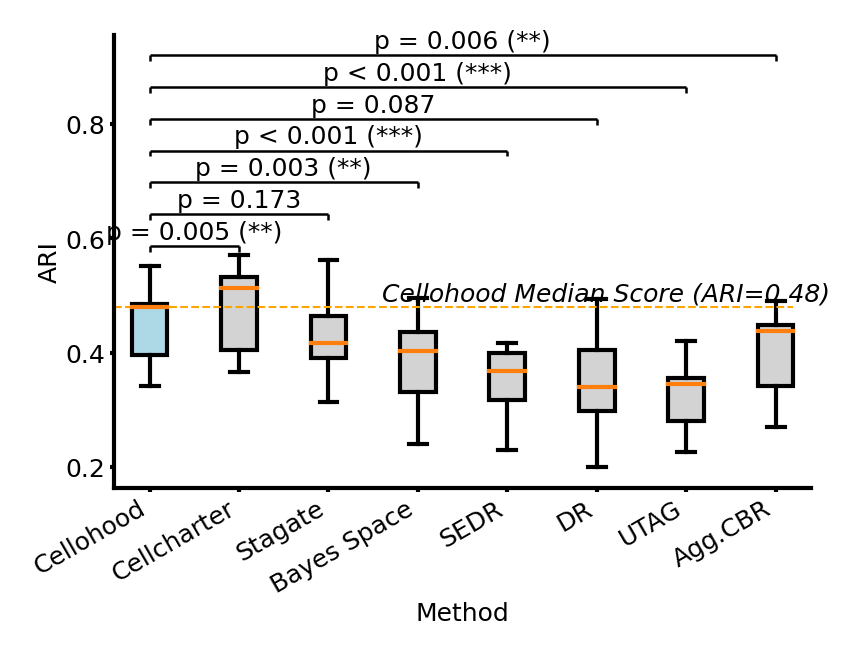

In [19]:
data_lists = ([train_means_mm] + list(method_to_results_means.values()) + [train_means])[::-1]
method_names = (['Agg.CBR'] + list(method_to_results_means.keys()) + ['Cellohood'])[::-1]

_ = plot_boxplot_with_stats_2(
    data_lists,
    method_names,
    0,
)

Now - let's setup the best clusterer:

In [20]:
sample_aris_df = pandas.DataFrame(
    sample_to_aris
)

best_clusterer = clusterers[sample_aris_df.mean(axis=1).argmax()]
predictions = best_clusterer.predict(plda_decomposed[:, variables])

## Diffusion prediction

Now - let's run and visualize diffusion-based analysis:

In [21]:
import pydiffmap

diffusion_transformer = pydiffmap.diffusion_map.DiffusionMap.from_sklearn(
    n_evecs=2, 
    epsilon=0.01, 
    alpha=.1, 
    k=64,
)

In [22]:
diffusion_transformer.fit(plda_decomposed[::20, [0, 1]] / decomposer.explained_variance_[:2] ** 0.5)
diffusion_transformed_ld = diffusion_transformer.transform(
    plda_decomposed[:, [0, 1]]  / decomposer.explained_variance_[:2] ** 0.5
)

/tmp/ipykernel_2867459/1580837843.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/1580837843.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/1580837843.py:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/1580837843.py:43: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/1580837843.py:64: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/1580837843.py:66: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6

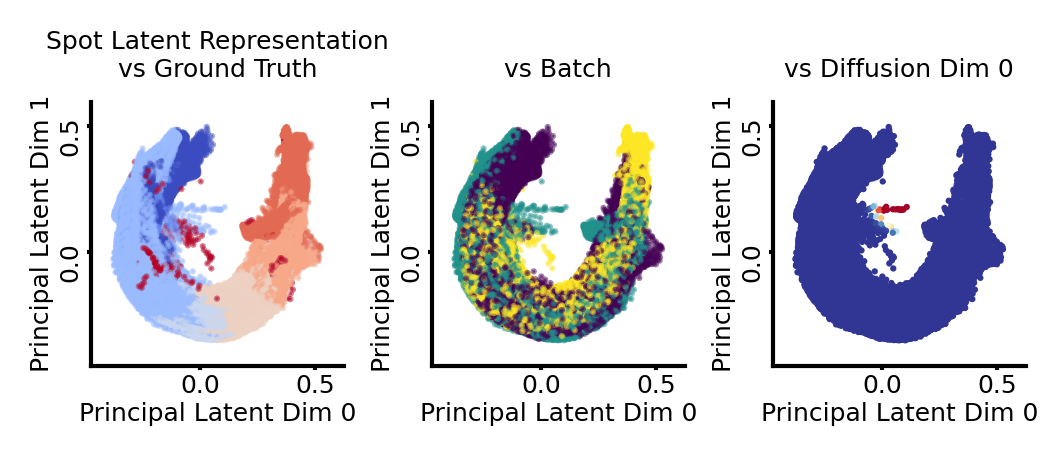

In [23]:
plt.figure(figsize=(3.5, 1.5), dpi=300)

plt.subplot(1, 3, 1)
plt.scatter(
    plda_decomposed[:, 0],
    plda_decomposed[:, 1],
    c=[true_layers_wu.index(x) for x in bag_cello_df.cell_df['layer']],
    s=0.5,
    cmap='coolwarm',
    alpha=0.5,
    vmax=7,
    vmin=0,
)
plt.xlim([plda_decomposed[:, 0].min() - 0.1, plda_decomposed[:, 0].max() + 0.1])
plt.ylim([plda_decomposed[:, 1].min() - 0.1, plda_decomposed[:, 1].max() + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Spot Latent Representation\nvs Ground Truth')

plt.subplot(1, 3, 3)
plt.scatter(
    plda_decomposed[:, 0],
    plda_decomposed[:, 1],
    c=-diffusion_transformed_ld[:, 0],
    s=0.5,
    cmap='RdYlBu',
)
plt.xlim([plda_decomposed[:, 0].min() - 0.1, plda_decomposed[:, 0].max() + 0.1])
plt.ylim([plda_decomposed[:, 1].min() - 0.1, plda_decomposed[:, 1].max() + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('\nvs Diffusion Dim 0')

random_perm = numpy.random.permutation(len(plda_decomposed[:, 0]))

plt.subplot(1, 3, 2)
plt.scatter(
    plda_decomposed[random_perm, 0],
    plda_decomposed[random_perm, 1],
    c=bag_cello_df.cell_df['batch'][random_perm],
    s=0.5,
    alpha=0.5,
)
plt.xlim([plda_decomposed[:, 0].min() - 0.1, plda_decomposed[:, 0].max() + 0.1])
plt.ylim([plda_decomposed[:, 1].min() - 0.1, plda_decomposed[:, 1].max() + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('\nvs Batch')
plt.tight_layout()


## Prediction visualization

For the visualization we will present the best clusterer scores:

In [24]:
sample_aris_df = pandas.DataFrame(
    sample_to_aris
)

best_clusterer = clusterers[sample_aris_df.mean(axis=1).argmax()]
predictions = best_clusterer.predict(plda_decomposed[:, variables])


pred_to_layer_assignment = {
    6: 'L1',
    1: 'L6',
    3: 'L5',
    2: 'L4',
    0: 'L2',
    5: 'L3',
    4: 'WM',
}

In [25]:
import seaborn as sns
import matplotlib


# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

matplotlib.font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'

/tmp/ipykernel_2867459/375178402.py:70: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/375178402.py:72: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/375178402.py:70: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/375178402.py:72: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/375178402.py:70: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/375178402.py:72: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


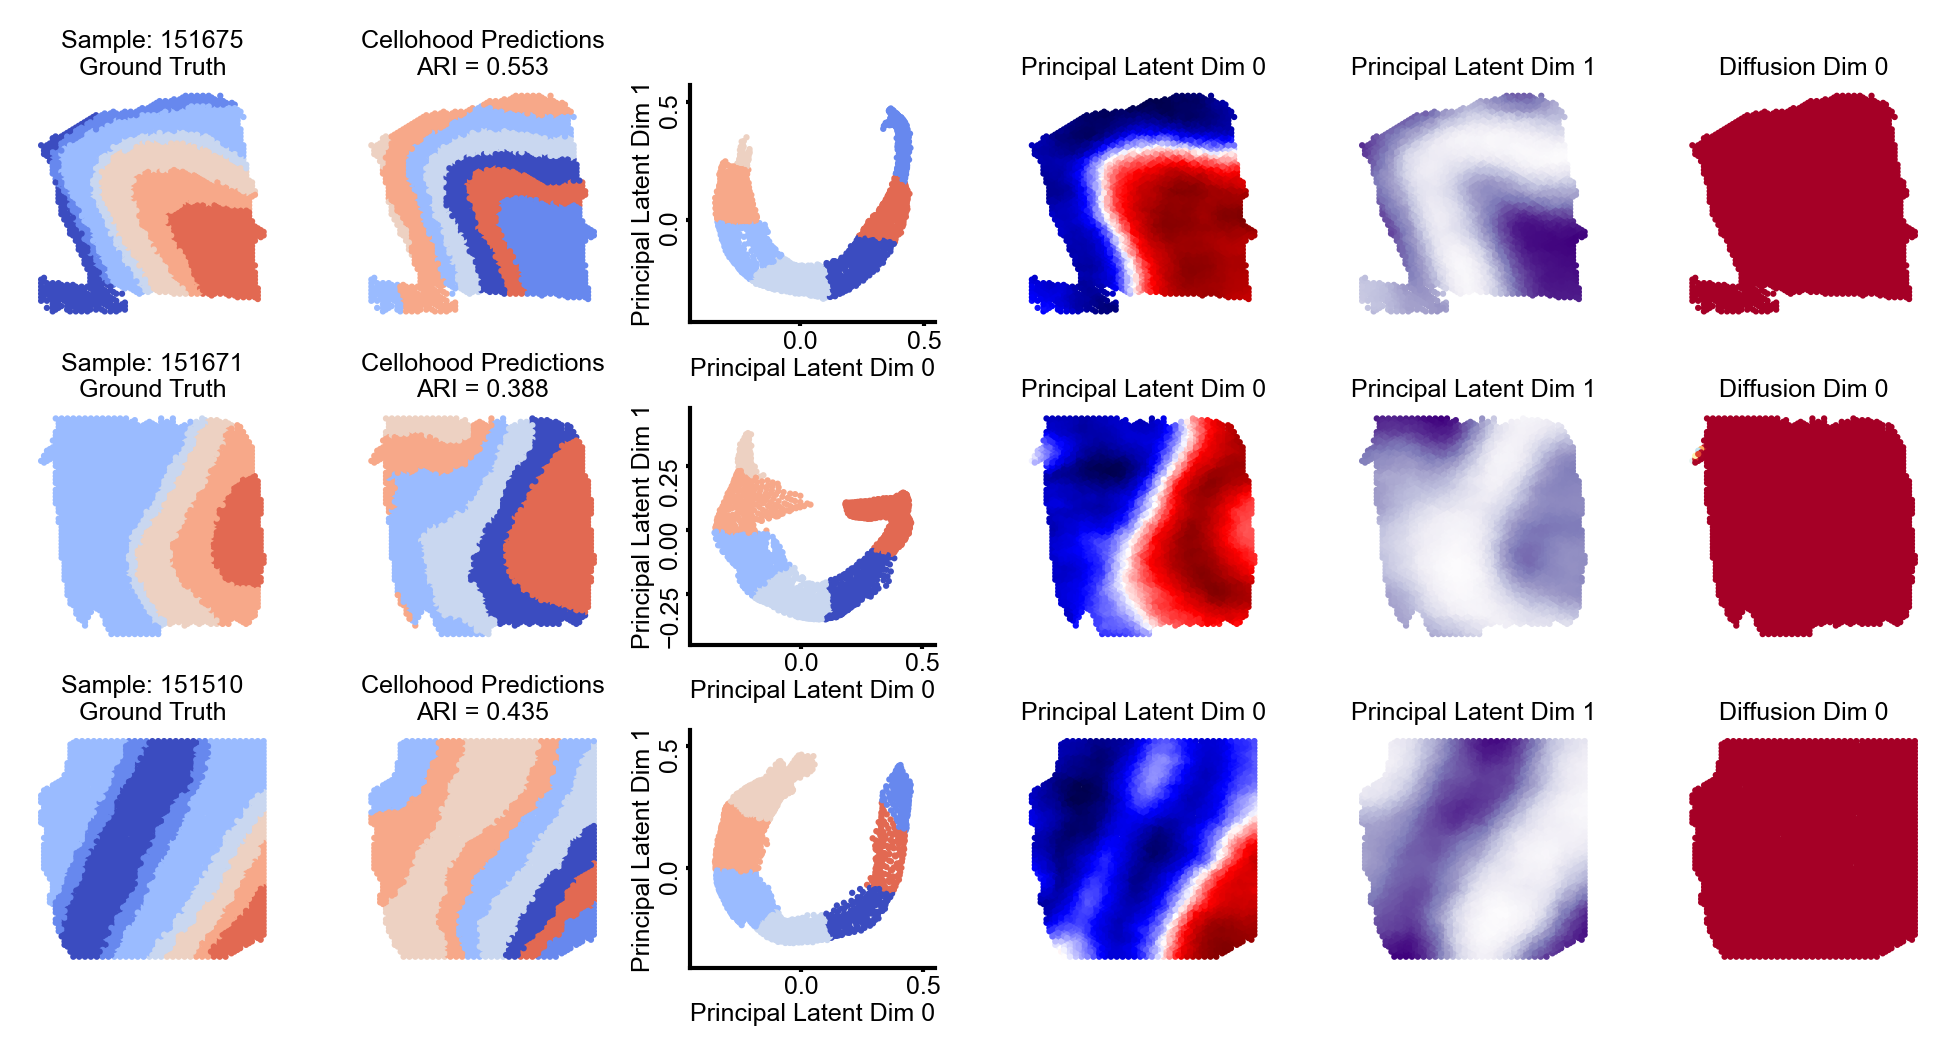

In [26]:
plt.figure(figsize=(6.5, 3.5), dpi=300)

PANEL_A_SAMPLES = [
    151675,
    151671,
    151510,
]


variables = [0, 1]



for sample_id, sample in enumerate(PANEL_A_SAMPLES):
    sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
    sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']

    sample_ld = plda_decomposed[bag_cello_df.cell_df['sample'] == sample][:, variables]
    sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
    sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
    sample_diff_d = diffusion_transformed_ld[bag_cello_df.cell_df['sample'] == sample]
    sample_diff_d = sample_diff_d[(sample_all_df['layer'] != 'UNK').values]

    sample_preds = best_clusterer.predict(sample_ld)
    current_ari = adjusted_rand_score(sample_preds, sample_gt)

    sample_to_aris[sample].append(current_ari)

    
    plt.subplot(3, 6, 6 * sample_id + 1)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_non_unk_df['layer'].apply(lambda x: true_layers.index(x)),
        cmap='coolwarm',
        s=0.5,
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Sample: {sample}\nGround Truth', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 2)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Cellohood Predictions\nARI = {round(current_ari, 3)}', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 3)
    plt.scatter(
        sample_ld[:, 0],
        sample_ld[:, 1],
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.xlim([sample_ld[:, 0].min() - 0.1, sample_ld[:, 0].max() + 0.1])
    plt.ylim([sample_ld[:, 1].min() - 0.1, sample_ld[:, 1].max() + 0.1])
    ax = plt.gca()
    ax.xaxis.set_tick_params(size=1, pad=1)
    ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
    ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.subplot(3, 6, 6 * sample_id + 4)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 0],
        s=0.5,
        vmin=sample_ld[:, 0].min(),
        vmax=sample_ld[:, 0].max(),
        cmap='seismic',
    )
    plt.axis('off')
    plt.title(f'Principal Latent Dim 0', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 5)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 1],
        s=0.5,
        cmap='Purples',
        vmin=sample_ld[:, 1].min(),
        vmax=sample_ld[:, 1].max(),
    )
    plt.axis('off')
    plt.title(f'Principal Latent Dim 1', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 6)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_diff_d[:, 0],
        s=0.5,
        cmap='RdYlBu',
        vmin=diffusion_transformed_ld[:, 0].min(),
        vmax=diffusion_transformed_ld[:, 0].max(),
    )
    plt.axis('off')
    plt.title(f'Diffusion Dim 0', pad=2.5, size=6)

plt.subplots_adjust(hspace=0.25, wspace=0.25)
plt.tight_layout()

## Supplementary: All Samples

In [27]:
SAMPLES_IN_ORDER = [
    151508,
    151509,
    151510,
    151507,
    151669,
    151670,
    151671,
    151672,
    151674,
    151675,
    151676,
    151673
]

SAMPLES_IN_PLOT_ORDER = SAMPLES_IN_ORDER[::4] + SAMPLES_IN_ORDER[1::4] + SAMPLES_IN_ORDER[2::4] + SAMPLES_IN_ORDER[3::4]

## Main Figure 2, Panel a

In [28]:
PANEL_A_SAMPLES = [
    151675,
    151671,
    151510,
]

/tmp/ipykernel_2867459/2113085574.py:58: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/2113085574.py:60: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/2113085574.py:58: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/2113085574.py:60: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/2113085574.py:58: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/2113085574.py:60: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6

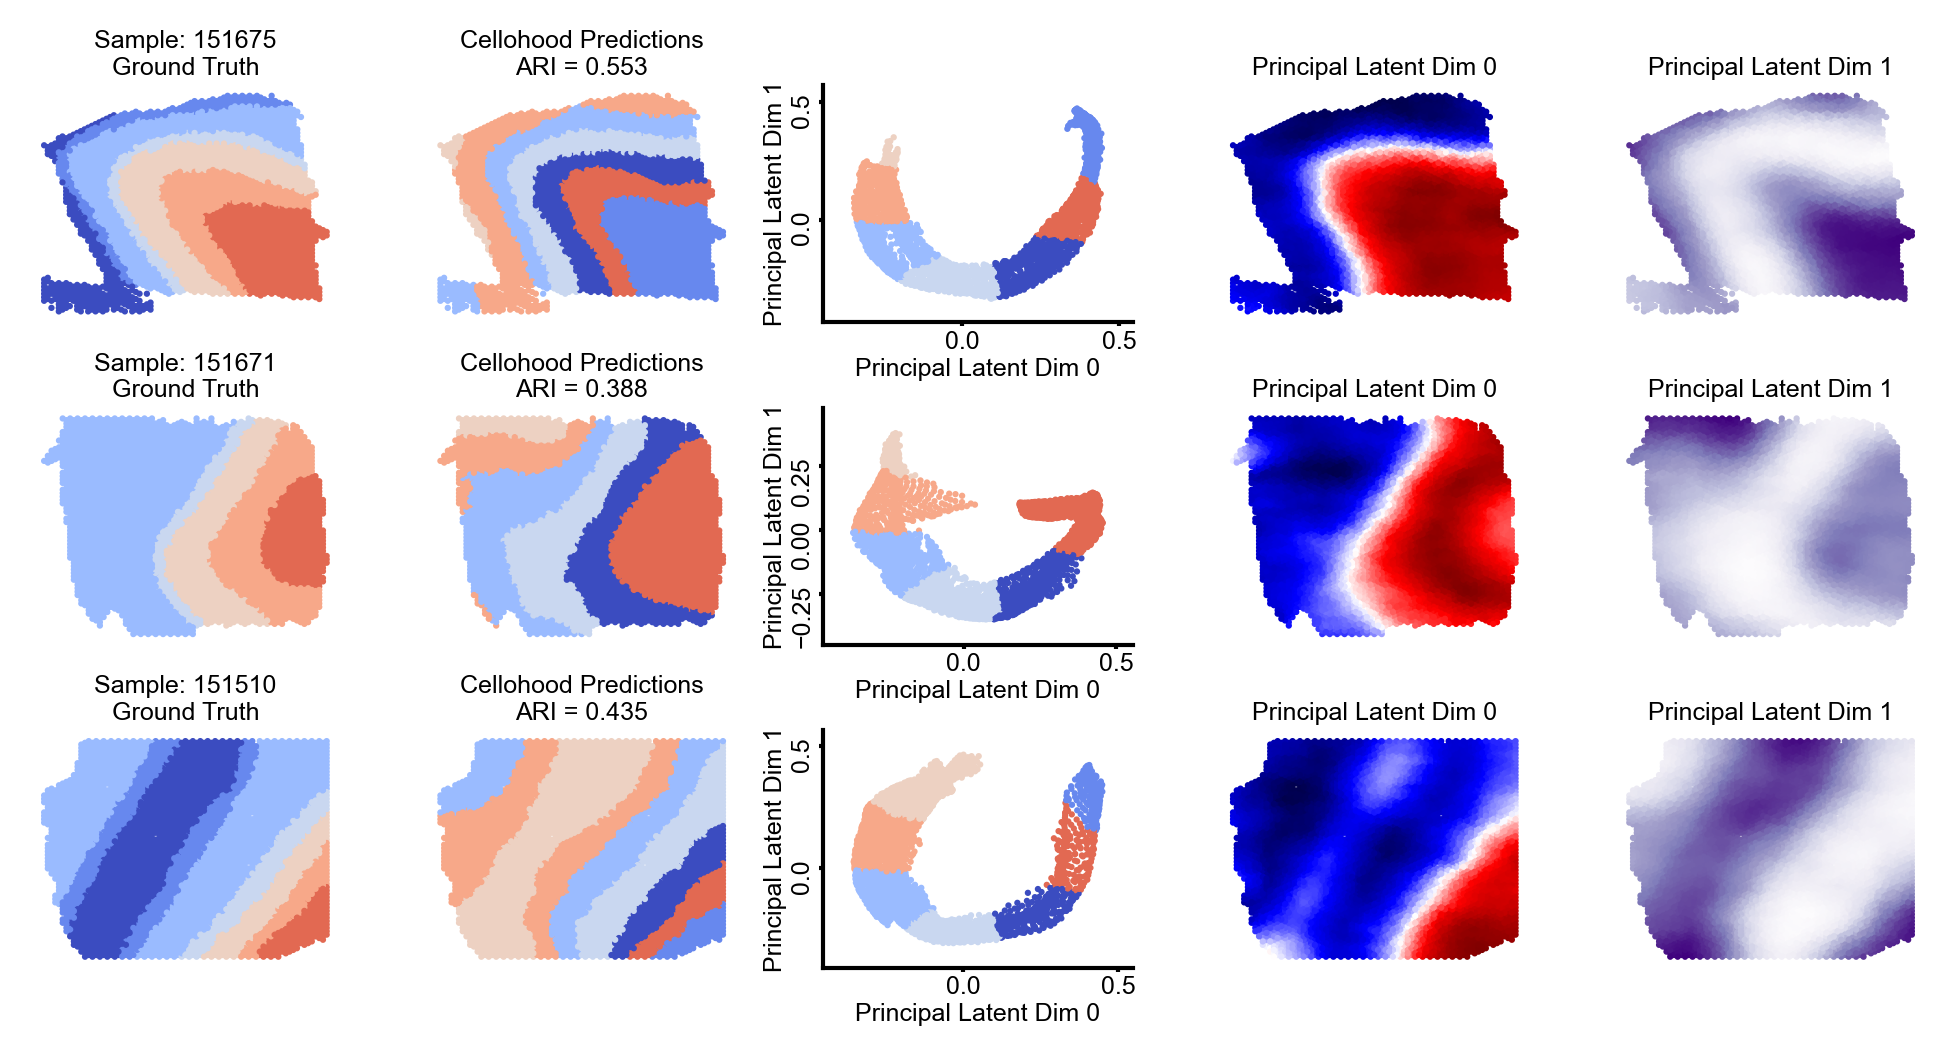

In [29]:
plt.figure(figsize=(6.5, 3.5), dpi=300)


for sample_id, sample in enumerate(PANEL_A_SAMPLES):
    sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
    sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']

    sample_ld = plda_decomposed[bag_cello_df.cell_df['sample'] == sample][:, variables]
    sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
    sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))

    sample_preds = best_clusterer.predict(sample_ld)
    current_ari = adjusted_rand_score(sample_preds, sample_gt)

    sample_to_aris[sample].append(current_ari)

    
    plt.subplot(3, 5, 5 * sample_id + 1)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_non_unk_df['layer'].apply(lambda x: true_layers.index(x)),
        cmap='coolwarm',
        s=0.5,
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Sample: {sample}\nGround Truth', pad=2.5, size=6)
    plt.subplot(3, 5, 5 * sample_id + 2)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Cellohood Predictions\nARI = {round(current_ari, 3)}', pad=2.5, size=6)
    plt.subplot(3, 5, 5 * sample_id + 3)
    plt.scatter(
        sample_ld[:, 0],
        sample_ld[:, 1],
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.xlim([sample_ld[:, 0].min() - 0.1, sample_ld[:, 0].max() + 0.1])
    plt.ylim([sample_ld[:, 1].min() - 0.1, sample_ld[:, 1].max() + 0.1])
    ax = plt.gca()
    ax.xaxis.set_tick_params(size=1, pad=1)
    ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
    ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.subplot(3, 5, 5 * sample_id + 4)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 0],
        s=0.5,
        vmin=sample_ld[:, 0].min(),
        vmax=sample_ld[:, 0].max(),
        cmap='seismic',
    )
    plt.axis('off')
    plt.title(f'Principal Latent Dim 0', pad=2.5, size=6)
    plt.subplot(3, 5, 5 * sample_id + 5)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 1],
        s=0.5,
        cmap='Purples',
        vmin=sample_ld[:, 1].min(),
        vmax=sample_ld[:, 1].max(),
    )
    plt.axis('off')
    plt.title(f'Principal Latent Dim 1', pad=2.5, size=6)

plt.subplots_adjust(hspace=0.25, wspace=0.25)
plt.tight_layout()

/tmp/ipykernel_2867459/3111265047.py:67: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/3111265047.py:69: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/3111265047.py:67: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/3111265047.py:69: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2867459/3111265047.py:67: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2867459/3111265047.py:69: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6

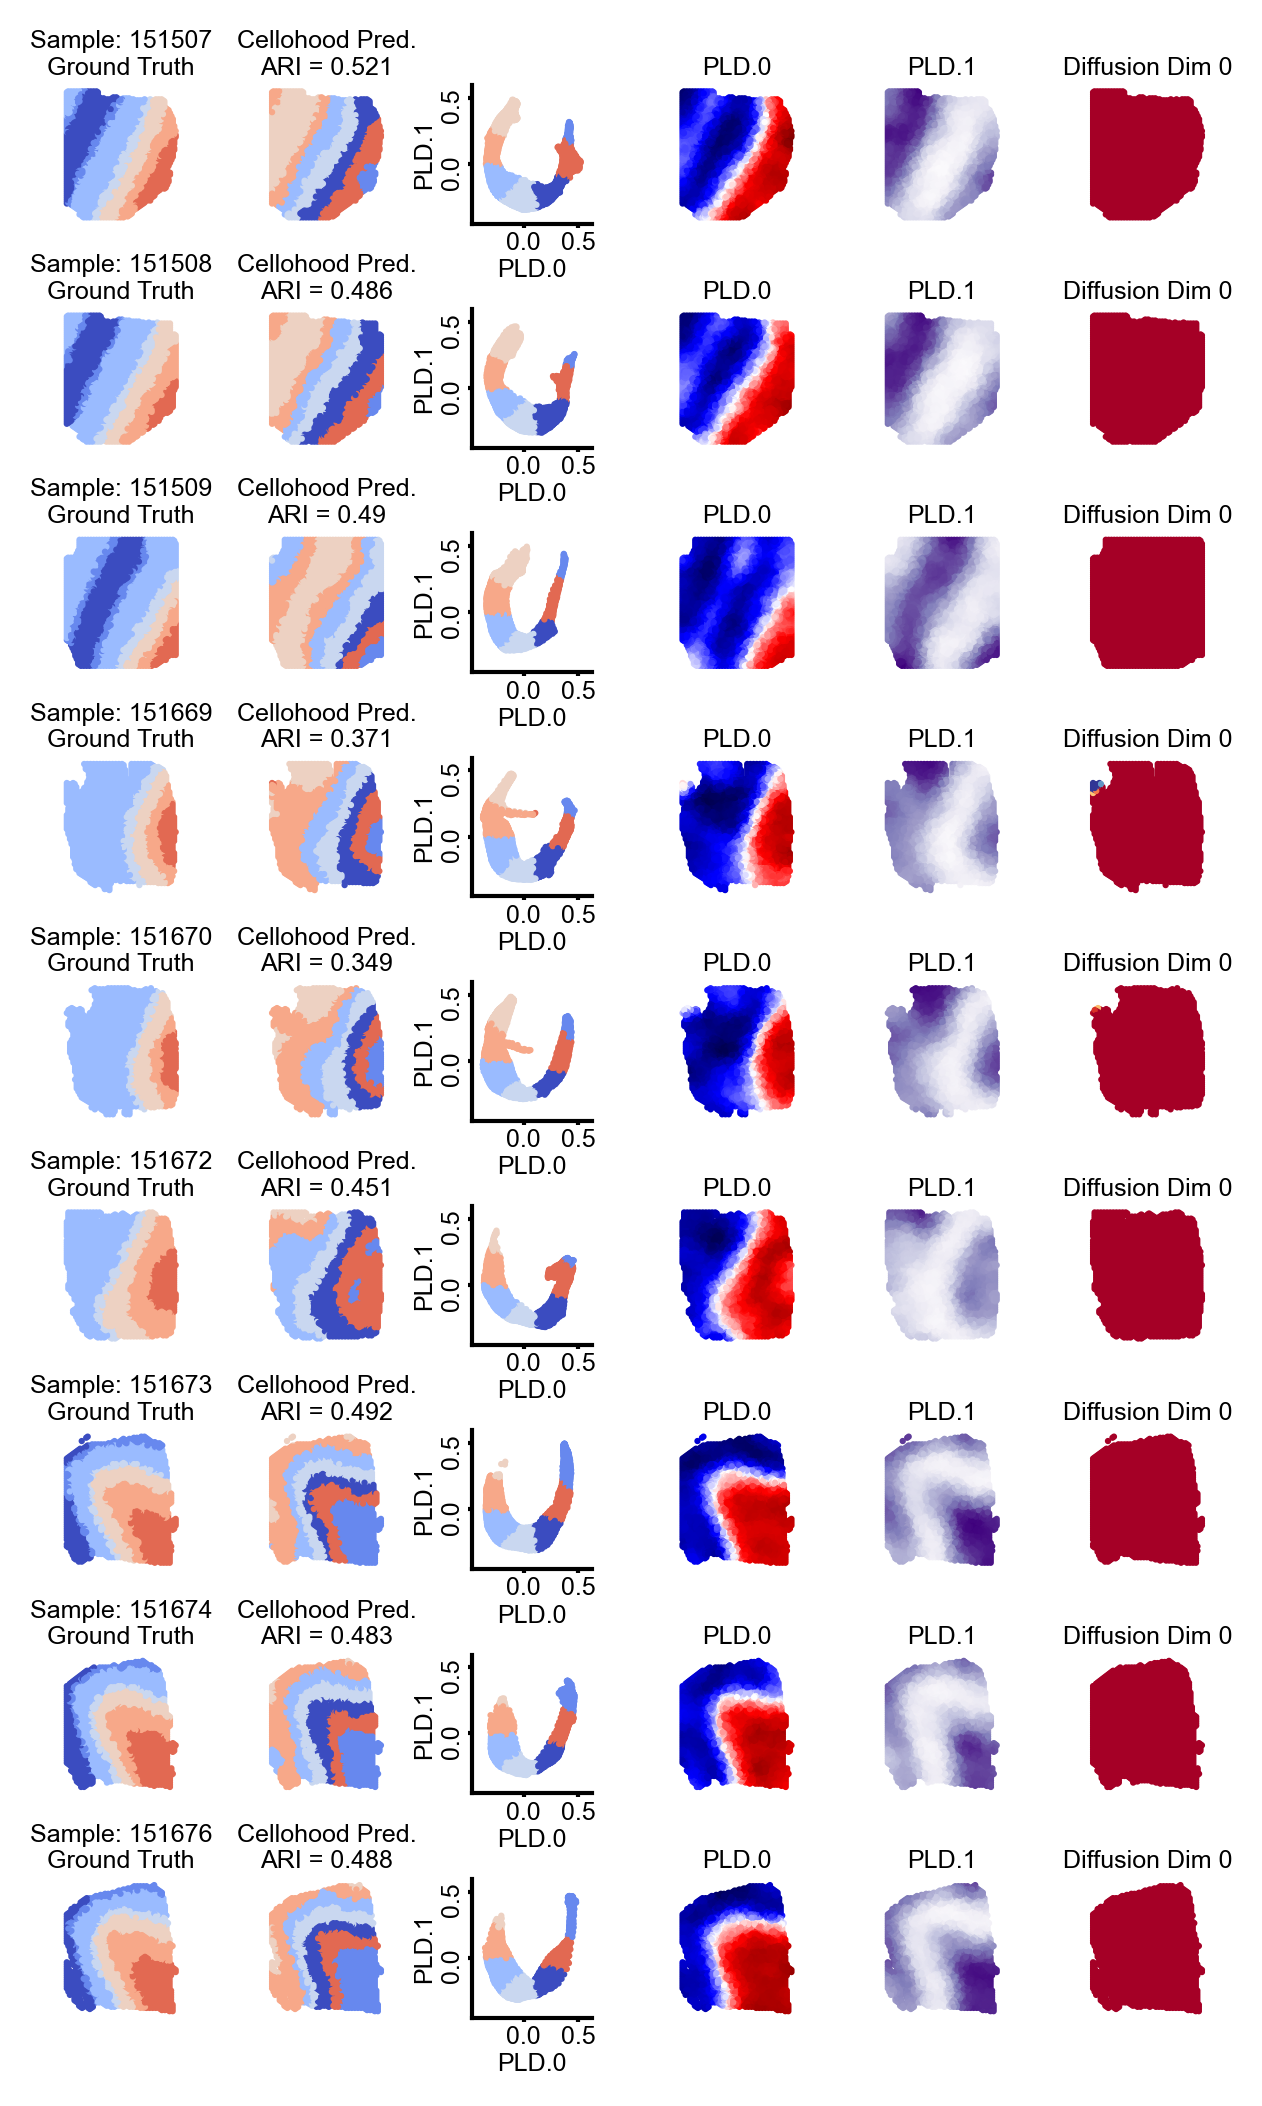

In [30]:
plt.figure(figsize=(4, 7), dpi=300)


variables = [0, 1]

ALL_SAMPLES = sorted(set(bag_cello_df.cell_df['sample']))
REST_SAMPLES = [sample for sample in ALL_SAMPLES if sample not in PANEL_A_SAMPLES]

for sample_id, sample in enumerate(REST_SAMPLES):
    if sample in PANEL_A_SAMPLES:
        continue
    sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
    sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']

    sample_ld = plda_decomposed[bag_cello_df.cell_df['sample'] == sample][:, variables]
    sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
    sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
    sample_diff_d = diffusion_transformed_ld[bag_cello_df.cell_df['sample'] == sample]
    sample_diff_d = sample_diff_d[(sample_all_df['layer'] != 'UNK').values]

    sample_preds = best_clusterer.predict(sample_ld)
    current_ari = adjusted_rand_score(sample_preds, sample_gt)

    sample_to_aris[sample].append(current_ari)

    
    plt.subplot(9, 6, 6 * sample_id + 1)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_non_unk_df['layer'].apply(lambda x: true_layers.index(x)),
        cmap='coolwarm',
        s=0.5,
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Sample: {sample}\nGround Truth', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 2)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Cellohood Pred.\nARI = {round(current_ari, 3)}', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 3)
    plt.scatter(
        sample_ld[:, 0],
        sample_ld[:, 1],
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.xlim([plda_decomposed[:, 0].min() - 0.1, plda_decomposed[:, 0].max() + 0.1])
    plt.ylim([plda_decomposed[:, 1].min() - 0.1, plda_decomposed[:, 1].max() + 0.1])
    ax = plt.gca()
    ax.xaxis.set_tick_params(size=1, pad=1)
    ax.set_xlabel('PLD.0', size=6, labelpad=1)
    ax.set_ylabel('PLD.1', size=6, labelpad=1)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.subplot(9, 6, 6 * sample_id + 4)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 0],
        s=0.5,
        vmin=plda_decomposed[:, 0].min(),
        vmax=plda_decomposed[:, 0].max(),
        cmap='seismic',
    )
    #plt.colorbar()
    plt.axis('off')
    plt.title(f'PLD.0', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 5)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 1],
        s=0.5,
        cmap='Purples',
        vmin=plda_decomposed[:, 1].min(),
        vmax=plda_decomposed[:, 1].max(),
    )
    plt.axis('off')
    plt.title(f'PLD.1', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 6)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_diff_d[:, 0],
        s=0.5,
        cmap='RdYlBu',
        vmin=diffusion_transformed_ld[:, 0].min(),
        vmax=diffusion_transformed_ld[:, 0].max(),
    )
    plt.axis('off')
    plt.title(f'Diffusion Dim 0', pad=2.5, size=6)
    
plt.subplots_adjust(hspace=0.25, wspace=0.25)
plt.tight_layout()

## Gene Program vs PLDA / Diffusion analysis

In [31]:
GENE_PROGRAMS_PATH = os.path.join(ZENODO_PATH, 'gene_programs')

zeng_gene_program = pandas.read_csv(
    os.path.join(GENE_PROGRAMS_PATH, 'Zeng_Markers.csv')
)
may_gene_program = pandas.read_excel(
    os.path.join(GENE_PROGRAMS_PATH, 'cortical layer marker gene list_1.xlsx'),
)

gene_expressions = pandas.read_csv(
    os.path.join(ZENODO_PATH, 'gene_expressions.csv')
)

In [32]:
gene_expressions = gene_expressions.iloc[bag_cello_df.cell_df['Unnamed: 0']]

In [33]:
all_genes = list(gene_expressions.columns)[1:-4]

In [34]:
zeng_genes = list(set(zeng_gene_program['Gene'].apply(lambda x: x.upper())) & set(all_genes))
may_genes = list(set(may_gene_program['Gene'].apply(lambda x: x.upper())) & set(all_genes))

In [35]:
zeng_gene_program['Gene'] = zeng_gene_program['Gene'].apply(lambda x: x.upper())
may_gene_program['Gene'] = may_gene_program['Gene'].apply(lambda x: x.upper())

In [36]:
zeng_gene_program.set_index('Gene', inplace=True)
may_gene_program.set_index('Gene', inplace=True)

In [37]:
import tqdm
import scipy


NB_OF_DIRECTIONS = 1

zang_and_may = list(set(zeng_genes + may_genes))


correlations = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))
correlations_p = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))


for s in range(NB_OF_DIRECTIONS):
    print(s)
    for marker_nb, marker in tqdm.tqdm(enumerate(zang_and_may)):
        result = scipy.stats.spearmanr(
            gene_expressions[marker], diffusion_transformed_ld[:, s]
        )
        correlations[marker_nb, s] = result.statistic
        correlations_p[marker_nb, s] = result.pvalue

0


81it [00:00, 163.27it/s]


In [38]:
NB_OF_DIRECTIONS = 2


correlations_d = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))
correlations_d_p = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))


for s in range(NB_OF_DIRECTIONS):
    print(s)
    for marker_nb, marker in tqdm.tqdm(enumerate(zang_and_may)):
        result = scipy.stats.spearmanr(
            gene_expressions[marker], plda_decomposed[:, s]
        )
        correlations_d[marker_nb, s] = result.statistic
        correlations_d_p[marker_nb, s] = result.pvalue

0


81it [00:00, 169.00it/s]


1


81it [00:00, 165.47it/s]


In [39]:
import tqdm
import scipy


NB_OF_DIRECTIONS = 1


correlations_all = numpy.zeros((len(all_genes), NB_OF_DIRECTIONS))
correlations_all_p = numpy.zeros((len(all_genes), NB_OF_DIRECTIONS))


for s in range(NB_OF_DIRECTIONS):
    print(s)
    for marker_nb, marker in tqdm.tqdm(enumerate(all_genes)):
        result = scipy.stats.spearmanr(
            gene_expressions[marker], diffusion_transformed_ld[:, s]
        )
        correlations_all[marker_nb, s] = result.statistic
        correlations_all_p[marker_nb, s] = result.pvalue

0


5000it [00:28, 174.26it/s]


In [40]:
zeng_inds = zeng_gene_program.loc[zeng_genes][list(zeng_gene_program.columns)[0:8]].copy()
may_inds = may_gene_program.loc[may_genes][list(may_gene_program.columns)[0:8]].copy()

In [41]:
zeng_colors = zeng_inds.applymap(lambda x: (0, 0, 0) if x else (1, 1, 1))
may_colors = may_inds.applymap(lambda x: (0, 0, 0) if x else (1, 1, 1))

In [42]:
zeng_col_to_layer = {
    '1': '1', 
    '2': '2', 
    '3': '3', 
    '4': '4', 
    '5': '5', 
    '6': '6', 
    '6b': '6', 
    'WM': 'WM',
}

In [43]:
may_col_to_layer = {
    1: '1',
    2: '2', 
    3: '3', 
    4: '4',
    '5a': '5', 
    '5b': '5', 
    6: '6',
    'SP': 'SP',
}

In [44]:
may_zeng_layers_cols = sorted(
    list(
        set(list(zeng_col_to_layer.values()) + list(may_col_to_layer.values()))
    )
)

In [45]:
may_zeng_layers_cols = may_zeng_layers_cols[:-2]

In [46]:
may_zeng_layers = pandas.DataFrame(
    numpy.zeros((len(zang_and_may), len(may_zeng_layers_cols))),
    index=zang_and_may,
    columns=may_zeng_layers_cols,
)

In [47]:
for _, row_ in may_gene_program.iterrows():
    for original_col, target_col in may_col_to_layer.items():
        if row_.name in zang_and_may and target_col in may_zeng_layers_cols:
            may_zeng_layers.iloc[
                zang_and_may.index(row_.name), 
                may_zeng_layers_cols.index(target_col)
            ] += int(row_[original_col])
            
            
for _, row_ in zeng_gene_program.iterrows():
    for original_col, target_col in zeng_col_to_layer.items():
        if row_.name in zang_and_may and target_col in may_zeng_layers_cols:
            may_zeng_layers.iloc[
                zang_and_may.index(row_.name), 
                may_zeng_layers_cols.index(target_col)
            ] += int(row_[original_col])

In [48]:
may_zeng_layers = may_zeng_layers > 0

In [49]:
avg_layer = (may_zeng_layers.values * numpy.arange(6)).sum(axis=1) / may_zeng_layers.values.sum(axis=1)

In [50]:
may_zeng_layers_colors = may_zeng_layers.applymap(lambda x: (0, 0, 0) if x else (0.9, 0.9, 0.9))

In [51]:
top_genes = [all_genes[int(ind_)] for ind_ in correlations_all[:, 0].argsort()[:20]]
bottom_genes = [all_genes[int(ind_)] for ind_ in correlations_all[:, 0].argsort()[-20:]]

In [52]:
import statsmodels.stats.multitest

_, q_vals, _, _ = statsmodels.stats.multitest.multipletests(
    correlations_p[:, 0], 
    alpha=0.2, 
    method='fdr_bh'
)

In [53]:
def convert_q_val_to_starts(q_val):
    result = ''
    if q_val < 0.2:
        result += '*'
    if q_val < 0.05:
        result += '*'
    if q_val < 0.01:
        result += '*'
    return result

In [54]:
result_q_val_starts = pandas.DataFrame([
    [convert_q_val_to_starts(x)]
    for x in q_vals],
    index=zang_and_may,
)

In [55]:
correlations_df = pandas.DataFrame(
    correlations,
    index=zang_and_may,
    columns=['Diffusion\nDim 0'],
)
correlations_df.index.name = 'Genes'


In [56]:
correlations_d_df = pandas.DataFrame(
    correlations_d,
    index=zang_and_may,
    columns=['PLD.0', 'PLD.1'],
)
correlations_d_df.index.name = 'Genes'


In [57]:
may_zeng_layers_colors.columns = [
    f'Layer {i}'
    for i in range(1, 6 + 1)
]

/tmp/ipykernel_2867459/388306975.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = may_cm.ax_cbar.set_yticklabels(may_cm.ax_cbar.get_yticklabels(), size=6)


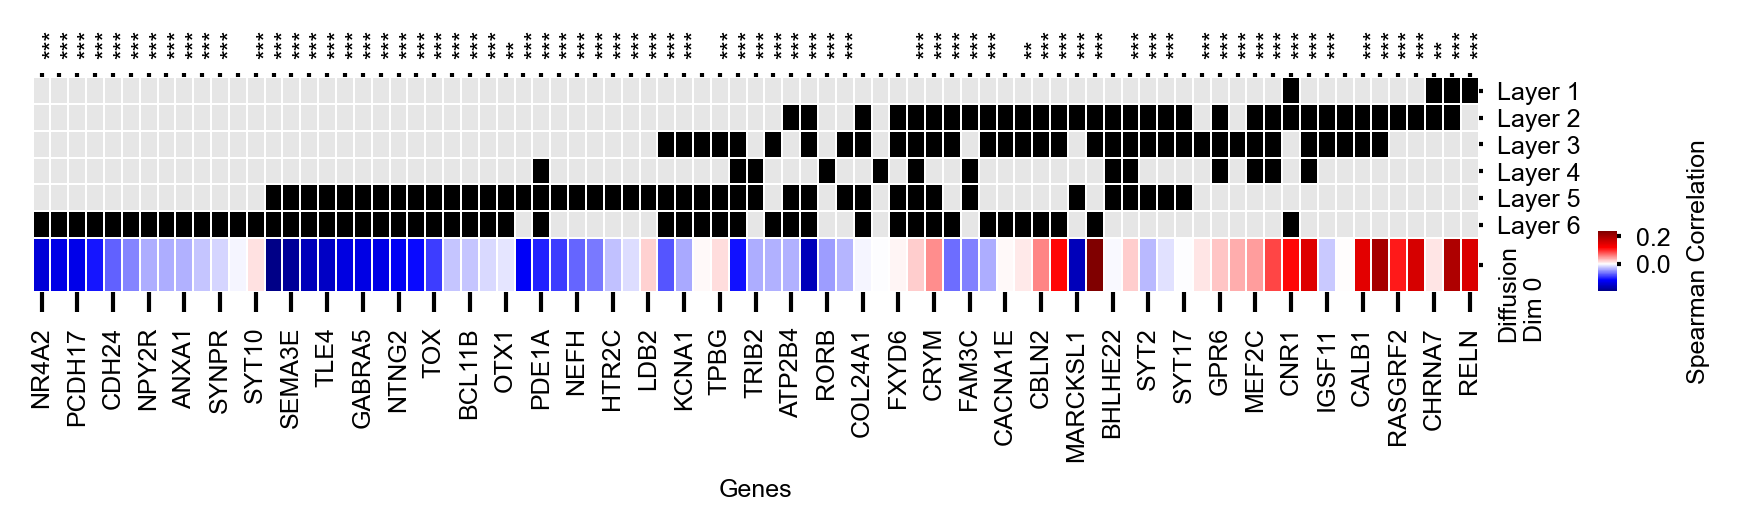

In [58]:
may_cm = sns.clustermap(
    correlations_df.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), :].T, 
    col_colors=may_zeng_layers_colors, 
    row_cluster=False,
    col_cluster=False,
    fmt='',
    annot_kws={'rotation': 90, 'ha': 'left', 'va': 'center'},
    center=0, 
    cmap='seismic',
    cbar_pos=(1., 0.1, 0.01, 0.2),
    colors_ratio=0.1,
    linewidth=0.01,
    cbar_kws={'label': 'Spearman Correlation'},
)

may_cm.fig.set_dpi(300)
may_cm.fig.set_size_inches((6.5, 1))

_ = may_cm.ax_heatmap.set_yticklabels(may_cm.ax_heatmap.get_yticklabels(), size=6)
_ = may_cm.ax_heatmap.set_xticklabels(may_cm.ax_heatmap.get_xticklabels(), size=6)

_ = may_cm.ax_col_colors.set_yticklabels(may_cm.ax_col_colors.get_yticklabels(), size=6)
_ = may_cm.ax_col_colors.yaxis.set_tick_params(size=1)
_ = may_cm.ax_heatmap.yaxis.set_tick_params(size=1)
_ = may_cm.ax_col_dendrogram.set_visible(False)
_ = may_cm.ax_row_dendrogram.set_visible(False)
_ = may_cm.ax_cbar.set_yticklabels(may_cm.ax_cbar.get_yticklabels(), size=6)
_ = may_cm.ax_cbar.yaxis.set_tick_params(size=1)


stars = list(result_q_val_starts.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), 0].T.values)

_ = may_cm.ax_col_colors.xaxis.set_tick_params(
    top=True, bottom=False, size=1, direction='out', labeltop=True, labelbottom=False)
_ = may_cm.ax_col_colors.set_xticks(
    [i + 0.5 for i in range(len(stars))],
    labels=stars,
    size=6,
)

_ = may_cm.ax_col_colors.set_xticklabels(
    labels=stars,
    size=6,
    rotation=90,
    va='bottom',
    ha='left',
)


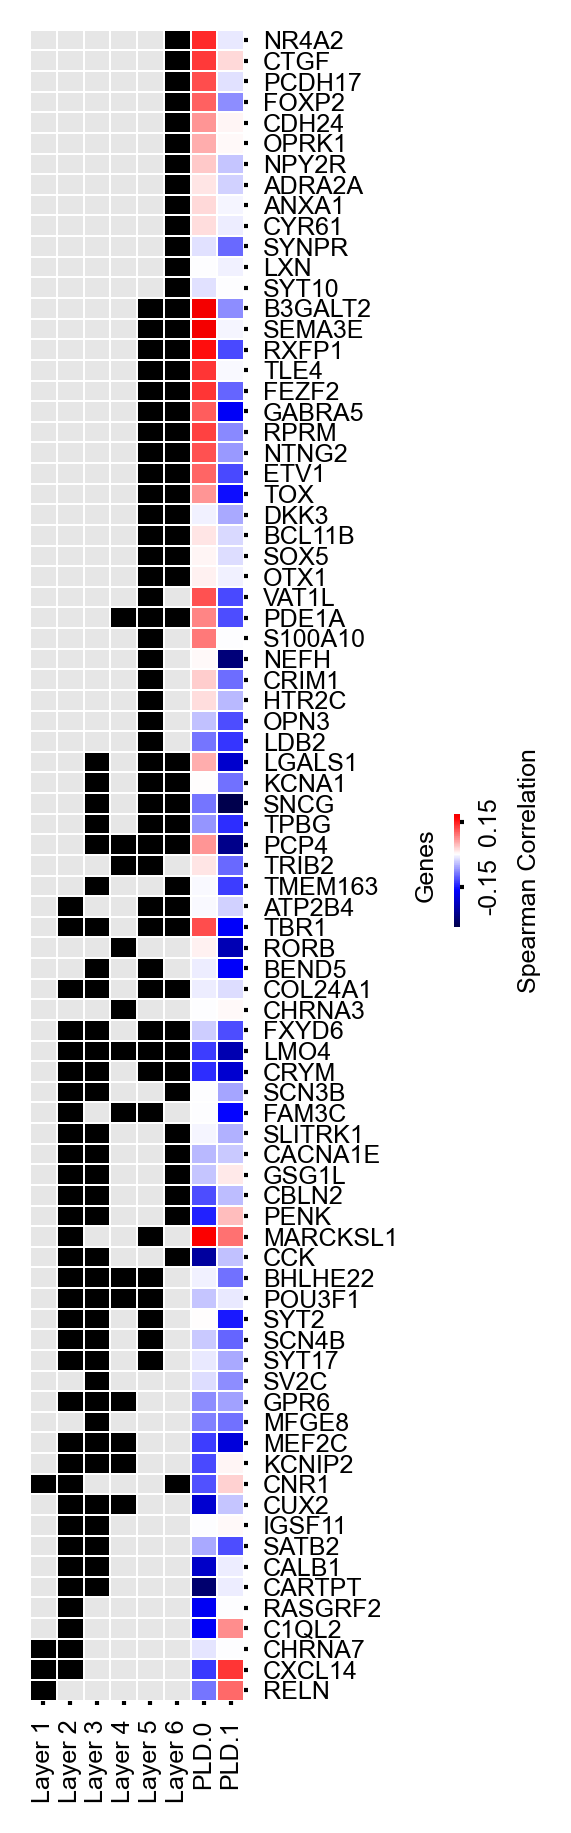

In [59]:
may_cm = sns.clustermap(
    correlations_d_df.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), :], 
    row_colors=may_zeng_layers_colors, 
    row_cluster=False,
    col_cluster=False,
    yticklabels=1,
    fmt='',
    center=0, 
    cmap='seismic',
    cbar_pos=(1.6, 0.405, 0.02, 0.05),
    colors_ratio=0.1,
    linewidth=0.01,
    cbar_kws={'label': 'Spearman Correlation'},
)

may_cm.fig.set_dpi(300)
may_cm.fig.set_size_inches((1, 7.5))

_ = may_cm.ax_heatmap.set_yticklabels(may_cm.ax_heatmap.get_yticklabels(), size=6, rotation=0)
_ = may_cm.ax_heatmap.set_xticklabels(may_cm.ax_heatmap.get_xticklabels(), size=6, rotation=90)

_ = may_cm.ax_row_colors.set_xticklabels(may_cm.ax_row_colors.get_xticklabels(), size=6)
_ = may_cm.ax_row_colors.xaxis.set_tick_params(size=1)
_ = may_cm.ax_heatmap.yaxis.set_tick_params(size=1)
_ = may_cm.ax_heatmap.xaxis.set_tick_params(size=1)
_ = may_cm.ax_col_dendrogram.set_visible(False)
_ = may_cm.ax_row_dendrogram.set_visible(False)
_ = may_cm.ax_cbar.set_yticks(
    [-.15, .15],
    [-.15, .15], 
    size=6, va='center')
_ = may_cm.ax_cbar.yaxis.set_tick_params(size=1, rotation=90)

## MISC 

For plotting / figure purposes:

/tmp/ipykernel_2867459/589620554.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


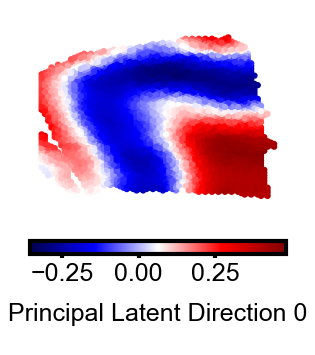

In [60]:
plt.figure(figsize=(1.1, 1.1), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_ld[:, 1],
    s=0.5,
    cmap='seismic',
    vmin=sample_ld[:, 0].min(),
    vmax=sample_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Direction 0')

/tmp/ipykernel_2867459/715629844.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


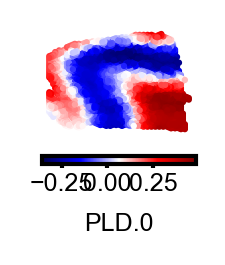

In [61]:
plt.figure(figsize=(0.66, 0.66), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_ld[:, 1],
    s=0.5,
    cmap='seismic',
    vmin=sample_ld[:, 0].min(),
    vmax=sample_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('PLD.0')

/tmp/ipykernel_2867459/3015756119.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


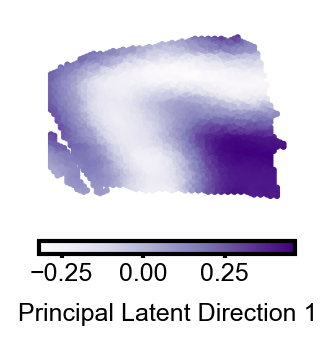

In [62]:
plt.figure(figsize=(1.1, 1.1), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_ld[:, 1],
    s=0.5,
    cmap='Purples',
    vmin=sample_ld[:, 1].min(),
    vmax=sample_ld[:, 1].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Direction 1')

## Layers Legend

(0.0, 1.0, 0.0, 1.0)

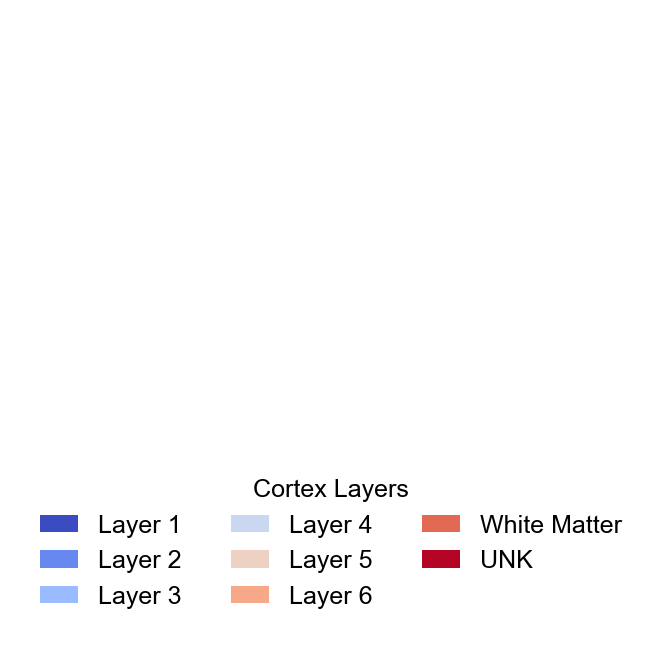

In [63]:
plt.figure(figsize=(1, 2), dpi=300)
handles = [
        matplotlib.patches.Patch(facecolor=plt.cm.coolwarm(i / 7)) for i in range(8)
]

legend = plt.legend(
    handles, 
    ['Layer 1', 'Layer 2', 'Layer 3', 'Layer 4', 'Layer 5', 'Layer 6', 'White Matter', 'UNK'], 
    title='Cortex Layers',
    loc=(-0.95, -0.3),
    frameon=False,
    ncols=3,
    handlelength=1.5,
    prop={'size': 6}
)

plt.axis('off')

## Diffusion direction colorbar

/tmp/ipykernel_2867459/532637280.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


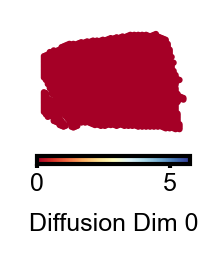

In [64]:
plt.figure(figsize=(0.66, 0.66), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_diff_d[:, 0],
    s=0.5,
    cmap='RdYlBu',
    vmin=diffusion_transformed_ld[:, 0].min(),
    vmax=diffusion_transformed_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Diffusion Dim 0')

/tmp/ipykernel_2867459/532637280.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


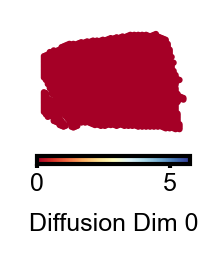

In [65]:
plt.figure(figsize=(0.66, 0.66), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_diff_d[:, 0],
    s=0.5,
    cmap='RdYlBu',
    vmin=diffusion_transformed_ld[:, 0].min(),
    vmax=diffusion_transformed_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Diffusion Dim 0')

/tmp/ipykernel_2867459/708998932.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


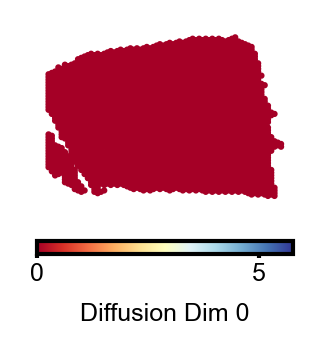

In [66]:
plt.figure(figsize=(1.1, 1.1), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_diff_d[:, 0],
    s=0.5,
    cmap='RdYlBu',
    vmin=diffusion_transformed_ld[:, 0].min(),
    vmax=diffusion_transformed_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Diffusion Dim 0')

## Batch Legend

(0.0, 1.0, 0.0, 1.0)

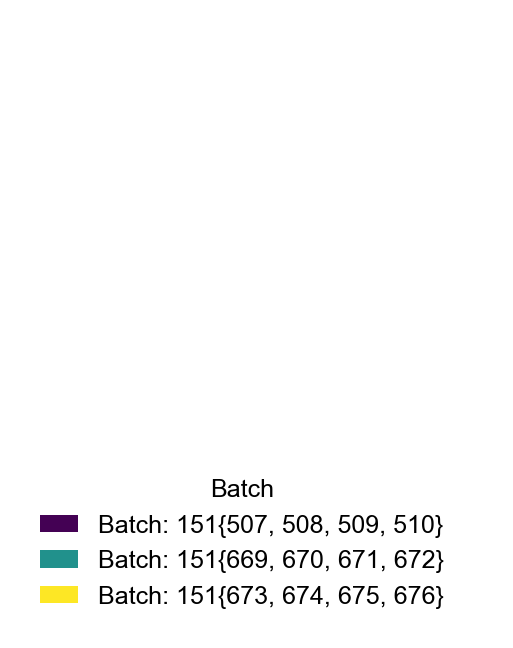

In [67]:
plt.figure(figsize=(1, 2), dpi=300)
handles = [
        matplotlib.patches.Patch(facecolor=plt.cm.viridis(i / 2)) for i in range(3)
]

legend = plt.legend(
    handles, 
    [
        'Batch: 151{507, 508, 509, 510}', 
        'Batch: 151{669, 670, 671, 672}', 
        'Batch: 151{673, 674, 675, 676}',
    ], 
    title='Batch',
    loc=(-0.95, -0.3),
    frameon=False,
    ncols=1,
    handlelength=1.5,
    prop={'size': 6}
)

plt.axis('off')